### 1, Read EMIT L2 surface reflectance data
### 2, Calculate band-averaged surface reflectance corresponding to RRTM 14 bands

In [2]:
import xarray as xr
import netCDF4,os,re,copy,glob,sys
import numpy as np
import matplotlib.pyplot as plt
import pickle
import cartopy
import sys,os,glob,datetime
import cartopy.crs as crs
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import seaborn as sns

# Add the parent directory's subdirectory to sys.path
sys.path.append(os.path.join(os.path.dirname('./'), '../EMIT_project_Zhibo'))
from EMIT_lib import *

In [2]:
EMIT_data_path_taki = '/umbc/xfs1/zzbatmos-new/common/Data/EMIT/'

### Function to read EMIT data products into a dictionary

In [3]:
def read_single_EMIT_granule_data(unique_time_stamp,
                                  products2read,
                                  EMIT_data_path = '/umbc/xfs1/zzbatmos-new/common/Data/EMIT/'):
    '''
    Inputs: 
    unique_time_stamp" '20231227T091713' the unique time stamp to track EMIT data
    products2read: list of products to read e.g., ['RAD','RFL','MIN']
    Outputs:
    RAD: Radiance data
    RFL: Surface reflectance data
    
    '''
    L1B_bucket_prefix=os.path.join(EMIT_data_path,'L1B/')
    RAD_file_prefix='EMIT_L1B_RAD_001_'
    OBS_file_prefix='EMIT_L1B_OBS_001_'
    L2A_bucket_prefix=os.path.join(EMIT_data_path,'L2A/')
    RFL_file_prefix='EMIT_L2A_RFL_001_'
    # MIN_bucket_prefix=os.path.join(EMIT_data_path,'L2B/')
    # MIN_file_prefix='EMIT_L2B_MIN_001_'
    EMIT_granule_data={}
    for d in products2read:
        if d=='RAD':
            bucket = os.path.join(L1B_bucket_prefix, RAD_file_prefix+unique_time_stamp)
            product_files =  glob.glob(bucket+'*.nc')
            print('***',product_files,len(product_files),product_files[0])
            if len(product_files) ==1:
                EMIT_granule_data[d]=xr.open_dataset(product_files[0])
                EMIT_granule_data[d+'_location']=xr.open_dataset(product_files[0],
                                                   group="/location")
                EMIT_granule_data[d+'_sensor_band_parameters']=xr.open_dataset(product_files[0],
                                                                               group="/sensor_band_parameters")
        elif d =='OBS':
            bucket = os.path.join(L1B_bucket_prefix, OBS_file_prefix+unique_time_stamp)
            product_files =  glob.glob(bucket+'*.nc')
            if len(product_files) ==1:
                EMIT_granule_data[d]=xr.open_dataset(product_files[0])
                EMIT_granule_data[d+'_location']=xr.open_dataset(product_files[0],
                                                   group="/location")
                EMIT_granule_data[d+'_sensor_band_parameters']=xr.open_dataset(product_files[0],
                                                                               group="/sensor_band_parameters")
        elif d =='RFL':
            bucket = os.path.join(L2A_bucket_prefix, RFL_file_prefix+unique_time_stamp)
            product_files =  glob.glob(bucket+'*.nc')
            for p in product_files:
                if 'RFLUNCERT' in p: 
                    continue
                else:
                    EMIT_granule_data[d]=xr.open_dataset(p)
                    EMIT_granule_data[d+'_sensor_band_parameters'] = xr.open_dataset(product_files[0],
                                                                               group="/sensor_band_parameters")
    return EMIT_granule_data

In [4]:
EGD=read_single_EMIT_granule_data('20230426T103717',['RAD','OBS','RFL'])

*** ['/umbc/xfs1/zzbatmos-new/common/Data/EMIT/L1B/EMIT_L1B_RAD_001_20230426T103717_2311607_006.nc'] 1 /umbc/xfs1/zzbatmos-new/common/Data/EMIT/L1B/EMIT_L1B_RAD_001_20230426T103717_2311607_006.nc


In [5]:
# EGD['OBS_location'].lon.values
# EGD['RFL_sensor_band_parameters'].wavelengths.values

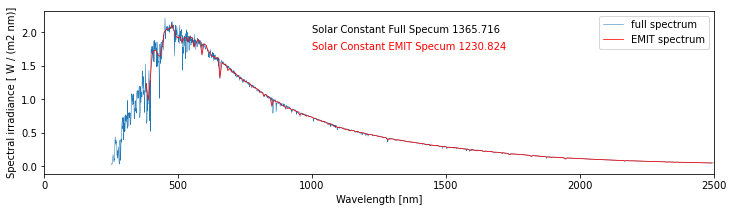

In [6]:
class kurudz_solar(object):
    def __init__(self):
        d=np.loadtxt('../EMIT_project_Zhibo/data/solar_flux/kurudz_1.0nm.dat',skiprows=12)
        self.wavelength = d[:,0]
        self.spectral_irradiance=d[:,1]/1000.0 # convert mW / (m2 nm) to W/m2/nm
        self.solar_constant = np.trapz(self.spectral_irradiance,self.wavelength)
        EMIT_wavelength = np.load('../EMIT_project_Zhibo/EMIT_wavelength.npz')['EMIT_wavelength']
        spectral_cover = (self.wavelength>= EMIT_wavelength[0]) & (self.wavelength<= EMIT_wavelength[-1])
        self.wavelength_EMIT = EMIT_wavelength
        self.spectral_irradiance_EMIT = np.interp(self.wavelength_EMIT,
                                                  self.wavelength,
                                                  self.spectral_irradiance)
        self.solar_constant_EMIT = np.trapz(self.spectral_irradiance_EMIT,self.wavelength_EMIT)
    def plot_spectral_irradiance(self,overlay_EMIT=False):
        fig,ax=plt.subplots(figsize=(12,3))
        ax.plot(self.wavelength,self.spectral_irradiance,lw='0.5',label='full spectrum')
        ax.set_xlabel('Wavelength [nm]')
        ax.set_ylabel('Spectral irradiance [ W / (m2 nm)]')
        #ax.set_title('Integrated solar constant {0:7.3f}'.format(self.solar_constant))
        ax.set_xlim([0,2500])
        if overlay_EMIT:
            ax.plot(self.wavelength_EMIT , self.spectral_irradiance_EMIT, c='r', lw='0.75',label='EMIT spectrum')
            ax.text(1000,2.0,'Solar Constant Full Specum {0:7.3f}'.format(self.solar_constant))
            ax.text(1000,1.75,'Solar Constant EMIT Specum {0:7.3f}'.format(self.solar_constant_EMIT),c='r')
            ax.legend(loc='upper right')
KS=kurudz_solar()
KS.plot_spectral_irradiance(overlay_EMIT=True)

In [7]:
def great_circle(lon0, lat0, lon_array, lat_array):
    arc = np.arccos(np.sin(np.radians(lat0)) * np.sin(np.radians(lat_array))
                 + np.cos(np.radians(lat0)) * np.cos(np.radians(lat_array)) 
                 * np.cos(np.radians(lon0 - lon_array)))
    return 6371 * arc

In [3]:
import read_Loeb05_ADM 
import importlib
importlib.reload(read_Loeb05_ADM)
ADM=read_Loeb05_ADM.Loeb05_ADM()

### Collocate EMIT and CERES in April 2023

In [9]:
# The filename (granule) of EMIT OBS and RAD L1B data; The time collocated CERES filename (granule); The index of CERES pixels located in the EMIT granule.
collocation_file_path='../EMIT_project_Zhibo/EMIT_CERES_collocation_taki/EMIT_TERRA_CERES_collocation/'
Collocate_file_list=glob.glob(collocation_file_path+'*.pkl') 
Ncases = len(Collocate_file_list)

CERES_cloud_fraction_threshold = 100.0 # the threshold for selecting clear-sky CERES SSF FOV
EMIT_CERES_distance_threshold = 20.0 # there radius to collocate EMIT pixels and CERES FOV. 
                                     # Compute the distance from EMIT pixels to a CERES FOV. 
                                     # smaller than this thredhold then EMIT pixels are in CERES FOV
        
EMIT_reflectance = []
CERES_reflectance = []


verbose=False

save_flux_comparison_result=True
save_emit_reflectance_result = True
raz_definition = 'ceres'

In [10]:
print(Collocate_file_list[0])

../EMIT_project_Zhibo/EMIT_CERES_collocation_taki/EMIT_TERRA_CERES_collocation/20230401T080827.pkl


In [11]:
for icase in range(0,Ncases):
            
    with open(Collocate_file_list[icase], 'rb') as pkl_file:
        collocation_data=pickle.load(pkl_file)  # CERES pixels located in the EMIT granule, 
                                                # Each file contains info of EMIT L1B OBS and RAD filename, CERES filename and CERES pixel index
                                                # Note, for EMIT filename, what we need is the time stamp
                
        # print(collocation_data)
        # sys.exit()
        
    pos = re.search('.pkl',Collocate_file_list[icase])
    EMIT_time_stamp=(Collocate_file_list[icase][pos.span()[0]-15:pos.span()[0]])
    print('processing case',icase,'out of',Ncases, EMIT_time_stamp)
    flux_comparison_results={}
    flux_comparison_results['EMIT_time_stamp']=EMIT_time_stamp
    
    CERES_data=xr.open_dataset('../EMIT_project_Zhibo/'+collocation_data['CERES_file_name'][0],engine='netcdf4')
    CERES_clear_fraction = CERES_data['Clear/layer/overlap percent coverages'].values[collocation_data['CERES_pixel_index'][0]][:,0]
    CERES_clear_sky_pixels = CERES_clear_fraction>=CERES_cloud_fraction_threshold
    
    #CERES pixels in EMIT granule and clear-sky pixels (two masks)
    CERES_flux = CERES_data['CERES SW TOA flux - upwards'].values[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels]
    CERES_radiance = CERES_data['CERES SW filtered radiance - upwards'].values[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels]
    CERES_radiance_unfiltered = CERES_data['CERES SW radiance - upwards'].values[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels]


    CERES_SZA=CERES_data['CERES solar zenith at surface'].values[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels]
    CERES_VZA=CERES_data['CERES viewing zenith at surface'].values[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels]
    CERES_RAZ=CERES_data['CERES relative azimuth at surface'].values[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels]
    CERES_F0=CERES_data['TOA Incoming Solar Radiation'].values[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels]
    
    CERES_S0=np.nanmean(CERES_F0/np.cos(np.radians(CERES_SZA))) #CERES solar constant (note, it contains seasonal variation)
    KS_CERES_S0_ratio = CERES_S0/KS.solar_constant
    

#     flux_comparison_results['CERES_Lon']=[]
#     flux_comparison_results['CERES_Lat']=[]
#     flux_comparison_results['CERES_S0']=[CERES_S0]
#     flux_comparison_results['CERES_Fup_based_on_ADM_filtered']=[]
#     flux_comparison_results['CERES_Fup_based_on_ADM_unfiltered']=[]
#     flux_comparison_results['CERES_Fup']=[]
#     flux_comparison_results['CERES_Fdn']=[]
#     flux_comparison_results['CERES_Ref']=[]
#     flux_comparison_results['CERES_Sza']=[]
#     flux_comparison_results['CERES_Vza']=[]
#     flux_comparison_results['CERES_Raz']=[]
    


#     flux_comparison_results['EMIT_Fup']=[] # EMIT spectrum 380nm-2500nm
#     flux_comparison_results['EMIT_Fup_fullspectrum']=[] #This 'full' spectrum means 315nm-2500nm
#     flux_comparison_results['EMIT_Fdn']=[]
#     flux_comparison_results['EMIT_Ref']=[]
#     flux_comparison_results['EMIT_Sza']=[]
#     flux_comparison_results['EMIT_Vza']=[]
#     flux_comparison_results['EMIT_Raz']=[]
#     flux_comparison_results['EMIT_Adm']=[]
    
#     flux_comparison_results['EMIT_wvl']=[]
#     flux_comparison_results['EMIT_surface_reflectance_flatten']=[]
#     flux_comparison_results['EMIT_surface_reflectance']=[]

    if CERES_clear_sky_pixels.sum() ==0: 
        continue
    EMIT_data_dict = read_single_EMIT_granule_data(EMIT_time_stamp,['OBS','RAD','RFL'])
    NCERES_clear = CERES_clear_sky_pixels.sum()
    
    for j in range(NCERES_clear):
        lon0=CERES_data['Longitude of CERES FOV at surface'].values[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels][j]
        lat0=90.0-CERES_data['Colatitude of CERES FOV at surface'].values[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels][j]
        # flux_comparison_results['CERES_Lon'].append(lon0)
        # flux_comparison_results['CERES_Lat'].append(lat0)
        EMIT_lon_array=EMIT_data_dict['OBS_location'].lon.values
        EMIT_lat_array=EMIT_data_dict['OBS_location'].lat.values
        EMIT_CERES_distance=great_circle(lon0,lat0,EMIT_lon_array,EMIT_lat_array)
        EMIT_pixels_in_CERES_FOV = (EMIT_CERES_distance<=EMIT_CERES_distance_threshold)

        EMIT_pixels_in_CERES_FOV_avg_radiance = EMIT_data_dict['RAD'].radiance.values[EMIT_pixels_in_CERES_FOV].mean(axis=0)        
        EMIT_pixels_in_CERES_SZA = EMIT_data_dict['OBS'].obs.values[:,:,4][EMIT_pixels_in_CERES_FOV].mean() # EMIT solar zenith angle (small variation so only needs mean)
        EMIT_pixels_in_CERES_VZA = EMIT_data_dict['OBS'].obs.values[:,:,2][EMIT_pixels_in_CERES_FOV].mean() # EMIT viewing zenith angle (small variation so only needs mean)
        
        EMIT_pixels_in_CERES_RAZ = EMIT_data_dict['OBS'].obs.values[:,:,1][EMIT_pixels_in_CERES_FOV].mean()-\
                                   EMIT_data_dict['OBS'].obs.values[:,:,3][EMIT_pixels_in_CERES_FOV].mean()
        
        # print(EMIT_data_dict['RFL_sensor_band_parameters'].wavelengths.values)
        # print( EMIT_data_dict['RFL'].reflectance.values.shape, EMIT_pixels_in_CERES_FOV.shape)
        EMIT_wvls = EMIT_data_dict['RFL_sensor_band_parameters'].wavelengths.values
        A = EMIT_data_dict['RFL'].reflectance.values[EMIT_pixels_in_CERES_FOV]
        EMIT_rfls = np.nanmean( np.where(A>0.0,A,np.nan), axis=0) #only keep surface reflectance larger than 0
#         print(EMIT_rfls)
#         print(EMIT_wvls)
        
#         sys.exit()

        if raz_definition =='ceres':
            EMIT_pixels_in_CERES_RAZ = 180.0-EMIT_pixels_in_CERES_RAZ
            # the definition of relative azimuth angle in CERES product
            # is the direction of viewing w.r.t. SUNLIGHT
            # while the relative azimuth angle of EMIT is defined as the viewing direction w.r.t. sun.  
        
        # print([EMIT_pixels_in_CERES_SZA],[EMIT_pixels_in_CERES_VZA],[EMIT_pixels_in_CERES_RAZ])
        # print( [CERES_SZA.values[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels][j]],
        #        [CERES_VZA.values[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels][j]],
        #        [CERES_RAZ.values[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels][j]])
        
        
        ADM_for_EMIT = ADM.interpolate_ADM([EMIT_pixels_in_CERES_SZA],[EMIT_pixels_in_CERES_VZA],[EMIT_pixels_in_CERES_RAZ])
        ADM_for_CERES = ADM.interpolate_ADM( [CERES_SZA[j]],
                                             [CERES_VZA[j]],
                                             [CERES_RAZ[j]])
        
        EMIT_Radiance = EMIT_pixels_in_CERES_FOV_avg_radiance/100 # convert uW/cm2/nm/sr to W/m2/nm/sr
        EMIT_Spectral_Irradiance = EMIT_Radiance *np.pi/ADM_for_EMIT[0]
        
        print(EMIT_Radiance.shape)
        print(EMIT_Spectral_Irradiance.shape)
        
        sys.exit()

        
#         #print(j,ADM_for_EMIT,ADM_for_CERES)
#         flux_comparison_results['CERES_Sza'].append(CERES_SZA[j])
#         flux_comparison_results['CERES_Vza'].append(CERES_VZA[j])
#         flux_comparison_results['CERES_Raz'].append(CERES_RAZ[j])
#         flux_comparison_results['CERES_Fup'].append(CERES_flux[j])
#         flux_comparison_results['CERES_Fup_based_on_ADM_filtered'].append(CERES_radiance[j]/ADM_for_CERES[0]*np.pi)
#         flux_comparison_results['CERES_Fup_based_on_ADM_unfiltered'].append(CERES_radiance_unfiltered[j]/ADM_for_CERES[0]*np.pi)

#         flux_comparison_results['CERES_Fdn'].append(CERES_F0[j])
#         flux_comparison_results['CERES_Ref'].append(CERES_flux[j]/CERES_F0[j])
#         # print('CERES Fup', flux_comparison_results['CERES_Fup'][-1],
#         #                    flux_comparison_results['CERES_Fup_based_on_ADM_filtered'][-1],
#         #                    flux_comparison_results['CERES_Fup_based_on_ADM_unfiltered'][-1])
#         EMIT_Fup = np.trapz(EMIT_pixels_in_CERES_FOV_avg_radiance,EMIT_data_dict['RAD_sensor_band_parameters'].wavelengths)*np.pi/100.0/ADM_for_EMIT[0]
#         wvl_mask = (EMIT_data_dict['RAD_sensor_band_parameters'].wavelengths <=420)
#         EMIT_Fup_380_420 = np.trapz(EMIT_pixels_in_CERES_FOV_avg_radiance[wvl_mask],EMIT_data_dict['RAD_sensor_band_parameters'].wavelengths[wvl_mask])*np.pi/100.0/ADM_for_EMIT[0]
#         EMIT_Fup_315_380 = 1.01*EMIT_Fup_380_420 + 4.86
#         EMIT_Fup_fullspectrum = EMIT_Fup + EMIT_Fup_315_380 #315nm to 2500nm
#         EMIT_Fdn = KS.solar_constant*KS_CERES_S0_ratio*np.cos(np.radians(EMIT_pixels_in_CERES_SZA)) # EMIT_Fdn is for full spectrum using CERES solar constant.
#         # print('EMIT_Fup',EMIT_Fup)
#         # print('EMIT_Fup_380_420',EMIT_Fup_380_420)
#         # print('EMIT_Fup_315_380',EMIT_Fup_315_380)
#         # print('EMIT_Fup_fullspectrum',EMIT_Fup_fullspectrum)
#         flux_comparison_results['EMIT_Fup'].append(EMIT_Fup)
#         flux_comparison_results['EMIT_Fup_fullspectrum'].append(EMIT_Fup_fullspectrum)
#         flux_comparison_results['EMIT_Fdn'].append(EMIT_Fdn)
#         flux_comparison_results['EMIT_Ref'].append(EMIT_Fup/EMIT_Fdn)  #Reflectance_prime
#         flux_comparison_results['EMIT_Sza'].append(EMIT_pixels_in_CERES_SZA)
#         flux_comparison_results['EMIT_Vza'].append(EMIT_pixels_in_CERES_VZA)
#         flux_comparison_results['EMIT_Raz'].append(EMIT_pixels_in_CERES_RAZ)
#         flux_comparison_results['EMIT_Adm'].append(ADM_for_EMIT[0])
        
        
#         flux_comparison_results['EMIT_wvl'].append(EMIT_wvls)
#         flux_comparison_results['EMIT_surface_reflectance'].append(EMIT_rfls)
#     if save_flux_comparison_result:  
#         save_file_name='Flux_Comparison_Surface_Reflectance_Data/flux_comparison_results_raz_ceres_'+EMIT_time_stamp+'.pkl'
#         with open(save_file_name,'wb') as dump_file:
#             pickle.dump(flux_comparison_results,dump_file)


processing case 0 out of 1782 20230401T080827


/tmp/ipykernel_242327/3473517339.py:32: RuntimeWarning: Mean of empty slice
  CERES_S0=np.nanmean(CERES_F0/np.cos(np.radians(CERES_SZA))) #CERES solar constant (note, it contains seasonal variation)


processing case 1 out of 1782 20230401T080839
processing case 2 out of 1782 20230401T080850
*** ['/umbc/xfs1/zzbatmos-new/common/Data/EMIT/L1B/EMIT_L1B_RAD_001_20230401T080850_2309106_007.nc'] 1 /umbc/xfs1/zzbatmos-new/common/Data/EMIT/L1B/EMIT_L1B_RAD_001_20230401T080850_2309106_007.nc
(285,)
(285,)


/tmp/ipykernel_242327/3473517339.py:89: RuntimeWarning: Mean of empty slice
  EMIT_rfls = np.nanmean( np.where(A>0.0,A,np.nan), axis=0) #only keep surface reflectance larger than 0


SystemExit: 

/umbc/xfs1/zzbatmos-new/users/cd11735/my_conda_env/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3465: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [12]:
print(EMIT_Radiance.shape)
print(EMIT_Spectral_Irradiance.shape)
print(EMIT_wvls.shape)
print(EMIT_wvls)

(285,)
(285,)
(285,)
[ 381.00558  388.4092   395.81583  403.2254   410.638    418.0536
  425.47214  432.8927   440.31726  447.7428   455.17035  462.59888
  470.0304   477.46292  484.89743  492.33292  499.77142  507.2099
  514.6504   522.0909   529.5333   536.9768   544.42126  551.8667
  559.3142   566.7616   574.20905  581.6585   589.108    596.55835
  604.0098   611.4622   618.9146   626.36804  633.8215   641.2759
  648.7303   656.1857   663.6411   671.09753  678.5539   686.0103
  693.4677   700.9251   708.38354  715.84094  723.2993   730.7587
  738.2171   745.6765   753.1359   760.5963   768.0557   775.5161
  782.97754  790.4379   797.89935  805.36176  812.8232   820.2846
  827.746    835.2074   842.66986  850.1313   857.5937   865.0551
  872.5176   879.98004  887.44147  894.90393  902.3664   909.82886
  917.2913   924.7538   932.21625  939.6788   947.14026  954.6027
  962.0643   969.5268   976.9883   984.4498   991.9114   999.37286
 1006.8344  1014.295   1021.7566  1029.2172  1036.6

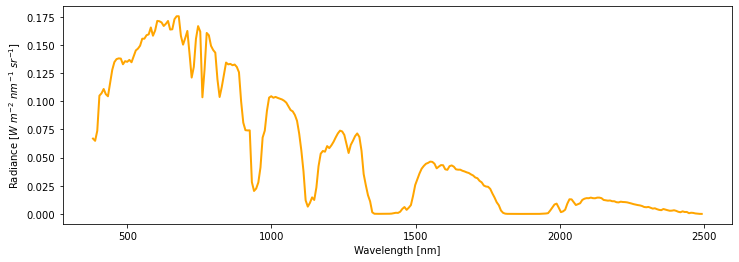

In [13]:
fig,ax=plt.subplots(figsize=[12,4])

ax.plot(EMIT_wvls,EMIT_Radiance,c='orange',lw=2)
ax.set_xlabel('Wavelength [nm]')
ax.set_ylabel(r'Radiance [$W\ m^{-2}\ nm^{-1} \ sr^{-1}$]')

plt.savefig('figures/EMIT_Radiance.png',dpi=300)

In [19]:
def index(wvls,wvl):
    indices = np.abs(wvls - wvl).argmin()
    return(indices)

In [30]:
rrtm_wn = np.array([22650,16000,12850,8050,7700,6150,5150,4650,4000])
rrtm_wvl = 1e7/rrtm_wn #nm
print(rrtm_wvl)

[ 441.50110375  625.          778.21011673 1242.23602484 1298.7012987
 1626.01626016 1941.74757282 2150.53763441 2500.        ]


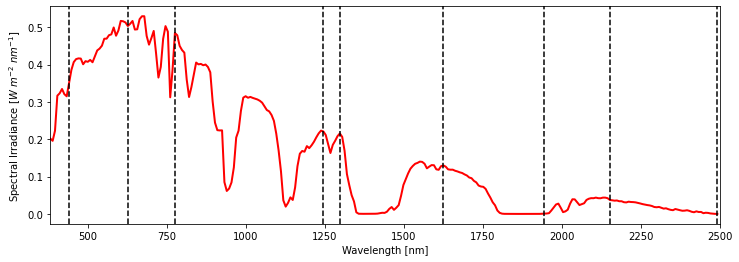

In [33]:
fig,ax=plt.subplots(figsize=[12,4])

ax.plot(EMIT_wvls,EMIT_Spectral_Irradiance,c='r',lw=2)
ax.set_xlabel('Wavelength [nm]')
ax.set_ylabel(r'Spectral Irradiance [$W\ m^{-2}\ nm^{-1} $]')


ax.axvline(EMIT_wvls[index(EMIT_wvls,rrtm_wvl[0])],c='k',ls='dashed')
ax.axvline(EMIT_wvls[index(EMIT_wvls,rrtm_wvl[1])],c='k',ls='dashed')
ax.axvline(EMIT_wvls[index(EMIT_wvls,rrtm_wvl[2])],c='k',ls='dashed')
ax.axvline(EMIT_wvls[index(EMIT_wvls,rrtm_wvl[3])],c='k',ls='dashed')
ax.axvline(EMIT_wvls[index(EMIT_wvls,rrtm_wvl[4])],c='k',ls='dashed')
ax.axvline(EMIT_wvls[index(EMIT_wvls,rrtm_wvl[5])],c='k',ls='dashed')
ax.axvline(EMIT_wvls[index(EMIT_wvls,rrtm_wvl[6])],c='k',ls='dashed')
ax.axvline(EMIT_wvls[index(EMIT_wvls,rrtm_wvl[7])],c='k',ls='dashed')
ax.axvline(EMIT_wvls[index(EMIT_wvls,rrtm_wvl[8])],c='k',ls='dashed')

ax.set_xlim(380,2500)
plt.savefig('figures/EMIT_Irradiance.png',dpi=300)

1.2422360248447204